In [ ]:
import numpy as np

import tensorflow
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Flatten, LeakyReLU, PReLU, ELU

from keras.datasets import fashion_mnist

import matplotlib.pyplot as plt

import warnings

warnings.filterwarnings('ignore')

In [4]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

X_train ,X_test = X_train / 255, X_test / 255 # Normalizing the data

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((60000, 28, 28), (10000, 28, 28), (60000,), (10000,))

# Basic Activation Functions

In [ ]:
def build_model(activation, depth = 10, units = 64):
    
    # Input layer
    model = Sequential([
        Input((28, 28)),
        Flatten()
    ])

    # Hidden Layers
    for _ in range(depth):
        model.add(Dense(units=units, activation=activation))

    # Output Layer
    model.add(Dense(10, activation='softmax'))

    model.compile(optimizer="Adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    return model

for act in ["sigmoid", "tanh", "relu"]:
    m = build_model(act)
    m.fit(X_train, y_train, epochs=10, validation_split=0.1, verbose=0)

# Vanishing Gradient Problem

In [14]:
class GradNormLogger(tensorflow.keras.callbacks.Callback):
    def __init__(self, x, y):
        super().__init__()
        self.x, self.y = x, y
        self.history = []

    def _norms(self):
        with tensorflow.GradientTape() as tape:
            preds = self.model(self.x, training=False)
            loss = tensorflow.reduce_mean(
                tensorflow.keras.losses.sparse_categorical_crossentropy(self.y, preds))
        grads = tape.gradient(loss, self.model.trainable_variables)
        return [float(tensorflow.sqrt(tensorflow.reduce_mean(tensorflow.square(g)))) for g in grads[::2]]

    def on_train_begin(self, logs=None):      # epoch "0": before any update
        self.history.append(self._norms())

    def on_epoch_end(self, epoch, logs=None):
        self.history.append(self._norms())

Text(0, 0.5, 'Gradient norm')

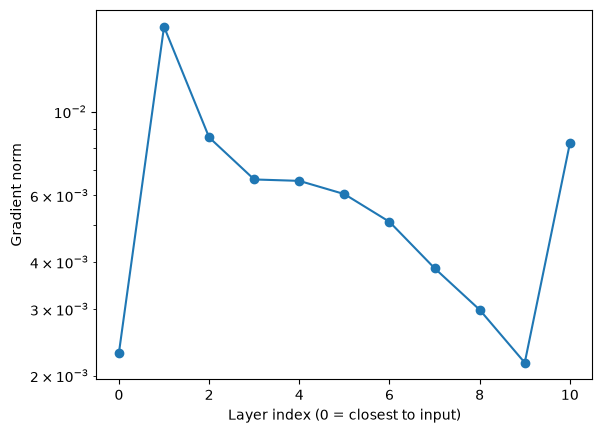

In [17]:
logger = GradNormLogger(X_train[:256], y_train[:256])
model = build_model("sigmoid", depth=10)
model.fit(X_train, y_train, epochs=10, callbacks=[logger], verbose=0)

norms = np.array(logger.history)            # shape: (epochs, layers)
plt.semilogy(norms[-1], marker="o")         # last epoch, log scale
plt.xlabel("Layer index (0 = closest to input)")
plt.ylabel("Gradient norm")

### We can see that the mean of the gradient in a layer is lower than the previous layer that show the gradient is vanishing. A tiny norm means the layer is barely learning 

# Dead Neuron Count in Dying ReLU Problem

In [12]:
def dead_fraction(model, x, layer_idx=1):
    probe = tensorflow.keras.Model(inputs=model.inputs,
                           outputs=model.layers[layer_idx].output)
    acts = probe(x)                                  # (samples, units)
    never_fires = tensorflow.reduce_max(acts, axis=0) == 0   # True per dead unit
    return tensorflow.reduce_mean(tensorflow.cast(never_fires, tensorflow.float32)).numpy()

In [13]:
def build_model(activation, lr, depth = 10, units = 64):
    
    # Input layer
    model = Sequential([
        Input((28, 28)),
        Flatten()
    ])

    # Hidden Layers
    for _ in range(depth):
        model.add(Dense(units=units, activation=activation))

    # Output Layer
    model.add(Dense(10, activation='softmax'))

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    return model

for lr in [0.001, 0.01, 0.1]:
    m = build_model("relu", depth=10, lr=lr)
    m.fit(X_train, y_train, epochs=10, verbose=0)
    print(lr, dead_fraction(m, X_train[:5000]))

c:\Users\Keval\OneDrive\Desktop\Deep-Learning-Journey\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_316']
Received: inputs=Tensor(shape=(5000, 28, 28))
  warnings.warn(msg)


0.001 0.125


c:\Users\Keval\OneDrive\Desktop\Deep-Learning-Journey\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_395']
Received: inputs=Tensor(shape=(5000, 28, 28))
  warnings.warn(msg)


0.01 0.875
0.1 0.84375


c:\Users\Keval\OneDrive\Desktop\Deep-Learning-Journey\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_474']
Received: inputs=Tensor(shape=(5000, 28, 28))
  warnings.warn(msg)
